# 06 · Transfer functions between search interest and media coverage

Notebooks 03 and 04 ask **whether** one series helps predict the other. This notebook asks
**how much, after how long, and for how long**: it estimates the *transfer function* from
Google Trends (GT) to MediaCloud (MC) and from MC to GT (Box, Jenkins, Reinsel & Ljung,
*Time Series Analysis: Forecasting and Control*).

For an input $x$ and an output $y$,

$$y_t = c + \nu_0 x_t + \nu_1 x_{t-1} + \nu_2 x_{t-2} + \dots + N_t ,$$

where $\nu_k$ is the response of $y$, $k$ days later, to a one-point rise of $x$ lasting one
day, and $N_t$ is autocorrelated noise (an AR($p$) process). Two forms are fitted
(`src/phc/transfer.py`):

* **distributed lag**: the weights $\nu_0,\dots,\nu_{14}$ are left free;
* **delay + decay**: $\nu_k = \omega\,\delta^{\,k-b}$ for $k\ge b$ and 0 before, i.e.
  $\nu(B)=\omega B^b/(1-\delta B)$. Three numbers summarise it: the **delay** $b$, the
  **total gain** $\omega/(1-\delta)$ and the **half-life** $\log(1/2)/\log\delta$.

### Three precautions

1. **The calendar is removed first.** The campaign calendar and the weekly cycle drive both
   series. Each series is split into a date profile (its average over the 11 seasons, one
   value per calendar date), a day-of-week effect, a season level and an **anomaly**. The
   transfer function is estimated on the anomalies: it describes how the day-to-day
   deviations of one series from its usual campaign shape are followed by deviations of the
   other.
2. **Same-day and lagged responses are reported separately.** With daily data, a same-day
   association ($\nu_0$) has no direction: it is the same correlation whichever series is
   called the input. Lagged weights ($\nu_1,\nu_2,\dots$) do have a direction. The lagged
   weights remain correctly estimated when the two series influence each other, because the
   past of the input cannot depend on today's noise; the same-day weight does not.
3. **The season is the unit of replication.** Null distributions come from season swaps
   (the input anomalies of each season are replaced by those of another season) and
   standard errors from deleting one season at a time. Both are checked on simulated data
   before use (Section 2).

The results describe predictive, lagged associations beyond the calendar. A news event
that raises coverage on one day and searches over the following days would produce the
same transfer function as coverage raising searches (Section 2, last scenario).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "phc").exists())
sys.path.insert(0, str(ROOT / "src"))

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from phc.config import CAMPAIGNS, FIG_DIR, TAB_DIR
from phc.granger import load_daily
from phc.kernel_granger import holm
from phc import transfer as T
from phc import simulate as S

# ---- parameters -----------------------------------------------------------
RECOMPUTE = False        # False: reuse results/cache/transfer.joblib if it exists
N_JOBS = -1
N_SURR = 999             # season-swap surrogates, real data (p-value resolution 0.001)
N_SURR_SIM = 99          # surrogates per simulated dataset
SIM_SEEDS = range(100)   # simulated datasets per scenario
HORIZON = T.K_FIR        # last lag of the distributed-lag model (14 days)
ALPHA = 0.05

CODES = ["OR", "Mov", "MB", "DJ"]
LABEL = {c: CAMPAIGNS[c].label for c in CODES}
DIRS = [("gt", "mc", "GT → MC"), ("mc", "gt", "MC → GT")]      # (input, output, label)
GT_COLOR, MC_COLOR = "#2a6fb0", "#e08a2c"
DIR_COLOR = {"GT → MC": GT_COLOR, "MC → GT": MC_COLOR}

CACHE = ROOT / "results" / "cache" / "transfer.joblib"
CACHE.parent.mkdir(parents=True, exist_ok=True)
cache = joblib.load(CACHE) if (CACHE.exists() and not RECOMPUTE) else {}


def cached(key, fn):
    """Compute fn() once and store the result in the cache file."""
    if key not in cache:
        t = time.time()
        cache[key] = fn()
        joblib.dump(cache, CACHE)
        print(f"[{key}] computed in {time.time() - t:.0f}s")
    else:
        print(f"[{key}] loaded from cache")
    return cache[key]


pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
data = {c: load_daily(c) for c in CODES}

## 1. Removing the calendar

Additive least-squares decomposition of each series:

$$x_{s,t} = \underbrace{m_{\text{date}(t)}}_{\text{campaign profile}} +
  \underbrace{w_{\text{weekday}(t)}}_{\text{weekly cycle}} +
  \underbrace{a_s}_{\text{season level}} + \underbrace{\tilde x_{s,t}}_{\text{anomaly}} .$$

The table gives the share of the variance of each series carried by each term (sequential
sums of squares, in the order profile, weekday, season).

In [2]:
def variance_shares(df):
    rows = {}
    for col in ("gt", "mc"):
        tot = df[col].var(ddof=0)
        v0 = T.anomalies(df, weekday=False, season=False)[col].var(ddof=0)
        v1 = T.anomalies(df, weekday=True, season=False)[col].var(ddof=0)
        v2 = T.anomalies(df, weekday=True, season=True)[col].var(ddof=0)
        rows[col.upper()] = {"campaign profile": 1 - v0 / tot, "weekday": (v0 - v1) / tot,
                             "season level": (v1 - v2) / tot, "anomaly": v2 / tot,
                             "anomaly SD (points)": np.sqrt(v2)}
    return pd.DataFrame(rows).T


shares = pd.concat({LABEL[c]: variance_shares(data[c]) for c in CODES}, names=["campaign", "series"])
shares.to_csv(TAB_DIR / "tf_variance_shares.csv")
shares.round(3)

campaign profile  weekday  season level  anomaly  anomaly SD (points)
campaign     series                                                                       
Octobre Rose GT                 0.736    0.008         0.182    0.074                4.954
             MC                 0.600    0.020         0.039    0.341               11.751
Movember     GT                 0.844    0.017         0.042    0.097                4.969
             MC                 0.152    0.032         0.029    0.787               15.910
Mars Bleu    GT                 0.229    0.087         0.360    0.323                9.855
             MC                 0.219    0.043         0.071    0.667               15.892
Dry January  GT                 0.529    0.002         0.128    0.340               14.345
             MC                 0.285    0.022         0.169    0.525               15.553

The campaign profile carries most of the variance of the search series of Octobre Rose and
Movember, and both series are lower at weekends (next figure). Both would be attributed to
the other series by a transfer function fitted to the raw data.

The weekly cycle matters for a second reason. A season-swap surrogate pairs a season with
another year **at the same calendar dates**, whose days of the week differ. The swap
therefore breaks the weekly cycle shared by the two series, and a test based on it can
mistake that cycle for a link. Removing the day-of-week effect before the swap avoids this;
notebook 04 quantifies the problem for the Granger tests (Section 7 there).

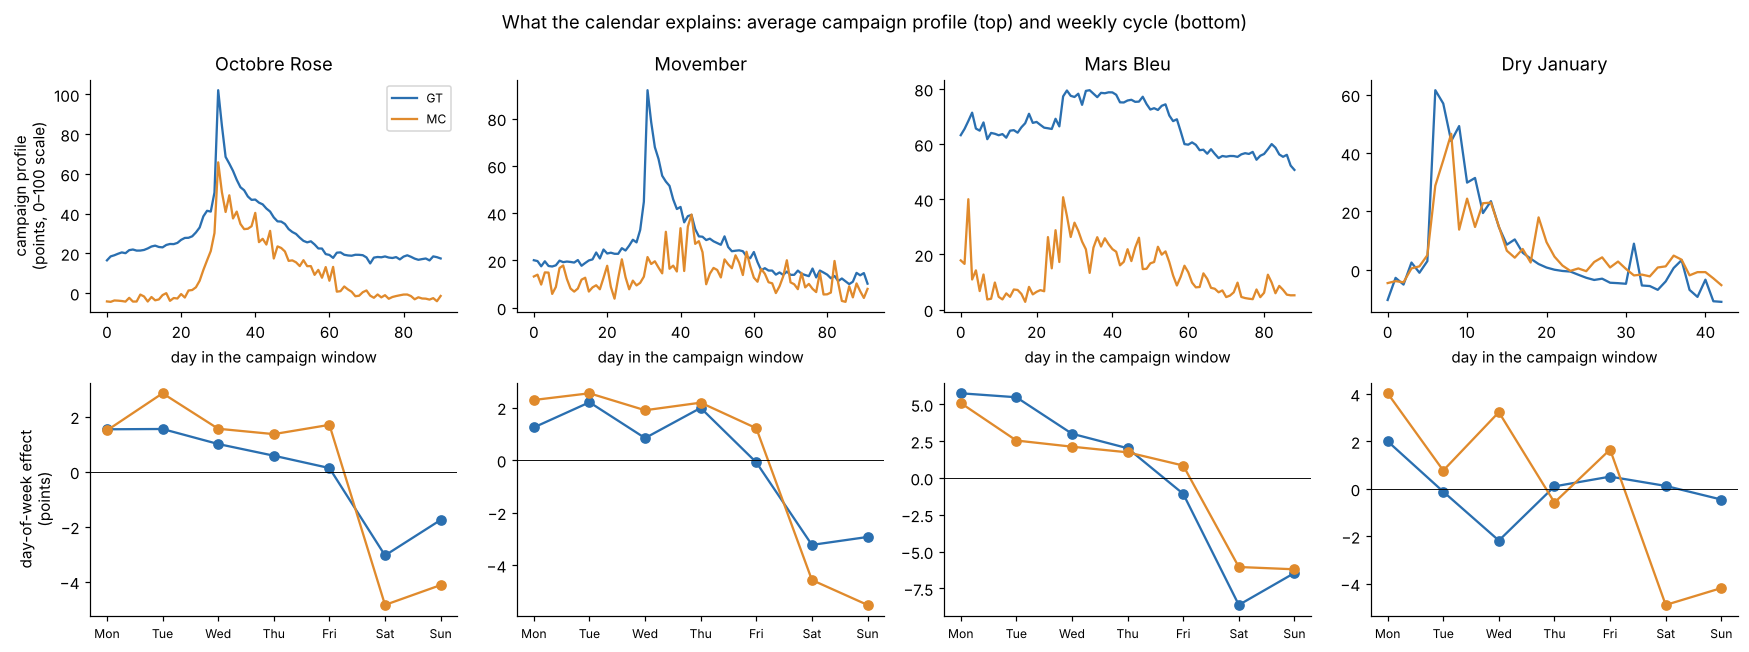

In [3]:
anom, comps = {}, {}
for c in CODES:
    anom[c], comps[c] = T.anomalies(data[c], return_components=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, c in enumerate(CODES):
    df = data[c]
    first = df[df["season"] == df["season"].iloc[0]]
    days = np.arange(len(first))
    for col, color, name in (("gt", GT_COLOR, "GT"), ("mc", MC_COLOR, "MC")):
        prof = T.panel(df.assign(v=comps[c][(col, "profile")]), "v")
        axes[0, j].plot(np.nanmean(prof, 0), color=color, lw=1.5, label=name)
        wd = pd.Series(comps[c][(col, "weekday")].to_numpy(), index=df.index.dayofweek).groupby(level=0).mean()
        axes[1, j].plot(range(7), wd.to_numpy(), marker="o", color=color, label=name)
    axes[0, j].set(title=LABEL[c], xlabel="day in the campaign window")
    axes[1, j].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=8)
    axes[1, j].axhline(0, color="black", lw=0.6)
axes[0, 0].set_ylabel("campaign profile\n(points, 0–100 scale)")
axes[1, 0].set_ylabel("day-of-week effect\n(points)")
axes[0, 0].legend(fontsize=8)
fig.suptitle("What the calendar explains: average campaign profile (top) and weekly cycle (bottom)")
fig.tight_layout()
fig.savefig(FIG_DIR / "tf01_calendar_components.png", dpi=200, bbox_inches="tight")

## 2. Validation on simulated systems

Before real data, the whole procedure (calendar removal, model selection, jackknife
intervals, surrogate tests) is run on systems with a known transfer function
(`simulate.transfer_system`, 11 seasons × 91 days). GT acts on MC with
$\nu_k = 0.5\times0.6^{\,k-1}$ for $k\ge1$ (delay 1 day, 14-day cumulative response 1.249,
half-life 1.36 days), on top of a campaign pulse and a weekly cycle shared by both series.

| Scenario | GT → MC | MC → GT |
|---|---|---|
| Link | true transfer function | none |
| Link with feedback | true transfer function | MC raises GT the next day ($\nu_k = 0.15\times0.5^{\,k-1}$, 14-day cumulative 0.300) |
| No link, fixed calendar | none | none |
| No link, calendar timing varies | none | none; the campaign pulse moves by up to ±15 days between seasons |

100 datasets per scenario, 99 surrogates per test.

In [4]:
SIM = {
    "Link": dict(),
    "Link with feedback": dict(feedback=0.15),
    "No link, fixed calendar": dict(omega=0.0),
    "No link, calendar timing varies": dict(omega=0.0, jitter=15),
}
TRUE_FWD = 0.5 * (1 - 0.6 ** HORIZON) / (1 - 0.6)       # lags 1..14 of 0.5 * 0.6^(k-1)
TRUE_BACK = 0.15 * (1 - 0.5 ** HORIZON) / (1 - 0.5)
SIM_TRUTH = {("Link", "GT → MC"): TRUE_FWD, ("Link", "MC → GT"): 0.0,
             ("Link with feedback", "GT → MC"): TRUE_FWD, ("Link with feedback", "MC → GT"): TRUE_BACK,
             ("No link, fixed calendar", "GT → MC"): 0.0, ("No link, fixed calendar", "MC → GT"): 0.0,
             ("No link, calendar timing varies", "GT → MC"): 0.0,
             ("No link, calendar timing varies", "MC → GT"): 0.0}


def sim_one(scenario, seed):
    df = S.transfer_system(seed, **SIM[scenario])
    rows = []
    for x, y, lab in DIRS:
        est = T.tf_summary(df, x, y)
        jk = T.jackknife(df, T.tf_summary, x=x, y=y)
        null = T.season_swap_null(df, x, y, n=N_SURR_SIM, seed=seed, p=est["p"])
        row = dict(scenario=scenario, seed=seed, direction=lab, b=est["b"], delta=est["delta"],
                   half_life=est["half_life"])
        for k in ("lagged", "same_day", "cum"):
            _, lo, hi = T.jackknife_interval(est[k], jk[k])
            row.update({k: est[k], f"{k}_lo": lo, f"{k}_hi": hi})
        row["p_lagged_fit"] = T.upper_p(est["r2_lagged"], null["r2_lagged"])
        row["p_lagged_sum"] = T.two_sided_p(est["lagged"], null["lagged"])
        row["p_same_day"] = T.two_sided_p(est["same_day"], null["same_day"])
        rows.append(row)
    return rows


sim_jobs = [(sc, seed) for sc in SIM for seed in SIM_SEEDS]
CHUNK = 20   # an interrupted run resumes from the last saved chunk
sim = pd.concat([
    cached(f"sim_{len(SIM_SEEDS)}_{i}", lambda chunk=sim_jobs[i:i + CHUNK]: pd.DataFrame(
        [r for rows in Parallel(n_jobs=N_JOBS)(delayed(sim_one)(*j) for j in chunk) for r in rows]))
    for i in range(0, len(sim_jobs), CHUNK)], ignore_index=True)

[sim_100_0] computed in 227s


[sim_100_20] computed in 239s


[sim_100_40] computed in 214s


[sim_100_60] computed in 215s


[sim_100_80] computed in 213s


[sim_100_100] computed in 255s


... (10 outputs left out)

[sim_100_320] computed in 244s


[sim_100_340] computed in 259s


[sim_100_360] computed in 270s


[sim_100_380] computed in 233s


In [5]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


rows = []
for (sc, lab), g in sim.groupby(["scenario", "direction"], sort=False):
    truth = SIM_TRUTH[sc, lab]
    link = truth != 0
    rows.append({
        "scenario": sc, "direction": lab, "true lagged response": round(truth, 3),
        "mean estimate": g["lagged"].mean(), "SD of estimates": g["lagged"].std(),
        "95% interval covers truth": np.mean((g["lagged_lo"] <= truth) & (truth <= g["lagged_hi"])),
        "delay = 1 selected": np.mean(g["b"] == 1) if link else np.nan,
        "median half-life": g["half_life"].median() if link else np.nan,
        "rejects: lagged fit": np.mean(g["p_lagged_fit"] < ALPHA),
        "rejects: lagged sum": np.mean(g["p_lagged_sum"] < ALPHA),
        "rejects: same day": np.mean(g["p_same_day"] < ALPHA),
    })
sim_table = pd.DataFrame(rows).set_index(["scenario", "direction"])
sim_table.to_csv(TAB_DIR / "tf_simulation.csv")
print(f"{len(SIM_SEEDS)} datasets per scenario; a true rate of 5% is observed between "
      f"{wilson(5, 100)[0]:.0%} and {wilson(5, 100)[1]:.0%}, a true coverage of 95% between "
      f"{wilson(95, 100)[0]:.0%} and {wilson(95, 100)[1]:.0%}")
sim_table.round(3)

100 datasets per scenario; a true rate of 5% is observed between 2% and 11%, a true coverage of 95% between 89% and 98%


true lagged response  mean estimate  SD of estimates  95% interval covers truth  delay = 1 selected  median half-life  rejects: lagged fit  rejects: lagged sum  \
scenario                        direction                                                                                                                                                                    
Link                            GT → MC                   1.249          1.252            0.121                       0.96                1.00             1.370                 1.00                 1.00   
                                MC → GT                   0.000         -0.113            0.121                       0.88                 NaN               NaN                 0.07                 0.28   
Link with feedback              GT → MC                   1.249          1.209            0.093                       0.96                1.00             1.322                 1.00                 1.00   
                                MC → GT                   0.300          0.185            0.100                       0.80                0.85             0.785                 0.80                 0.49   
No link, fixed calendar         GT → MC                   0.000          0.007            0.123                       0.96                 NaN               NaN                 0.01                 0.06   
                                MC → GT                   0.000         -0.043            0.183                       0.92                 NaN               NaN                 0.04                 0.10   
No link, calendar timing varies GT → MC                   0.000          0.147            0.107                       0.78                 NaN               NaN                 0.53                 0.12   
                                MC → GT                   0.000          0.531            0.120                       0.07                 NaN               NaN                 0.94                 0.92   

                                           rejects: same day  
scenario                        direction                     
Link                            GT → MC                 0.01  
                                MC → GT                 0.05  
Link with feedback              GT → MC                 0.01  
                                MC → GT                 0.04  
No link, fixed calendar         GT → MC                 0.02  
                                MC → GT                 0.05  
No link, calendar timing varies GT → MC                 0.53  
                                MC → GT                 0.52

*Reading the table.* "Lagged response" is $\nu_1+\dots+\nu_{14}$ of the distributed-lag
model. "Rejects" columns give the share of datasets with a surrogate p-value below 0.05:
*lagged fit* tests whether lags 1–14 improve the fit beyond the same-day term, *lagged sum*
whether their sum differs from zero, *same day* whether $\nu_0$ differs from zero.
The conclusions drawn from this table are written in Section 7, after the real data.

## 3. Identification: cross-correlation after pre-whitening

A model-free look at the lag structure. An AR model is fitted to the input anomalies and
the same filter is applied to the output; the cross-correlation of the two filtered series
at lag $k$ is then proportional to $\nu_k$. In each panel, **positive lags** mean that the
input leads the output; **negative lags** mean that the output leads the input (feedback).

Grey band: 95% range of the cross-correlation at each lag over 999 season-swap surrogates.
Dotted lines: the level exceeded at *any* of the 29 lags by 5% of the surrogates (a
simultaneous band, which accounts for looking at many lags).

[ccf] computed in 3s


,campaign,input,output,lag,ccf,null_lo,null_hi,simultaneous_band,outside_simultaneous_band
43,Movember,GT,MC,0,0.160,-0.073,0.042,0.109,True
72,Mars Bleu,GT,MC,0,0.120,-0.080,0.065,0.113,True
100,Dry January,GT,MC,-1,0.187,-0.106,0.099,0.157,True
146,Movember,MC,GT,-13,0.109,-0.082,0.062,0.108,True
159,Movember,MC,GT,0,0.160,-0.077,0.044,0.108,True
188,Mars Bleu,MC,GT,0,0.136,-0.082,0.051,0.112,True
217,Dry January,MC,GT,0,0.218,-0.136,0.083,0.183,True


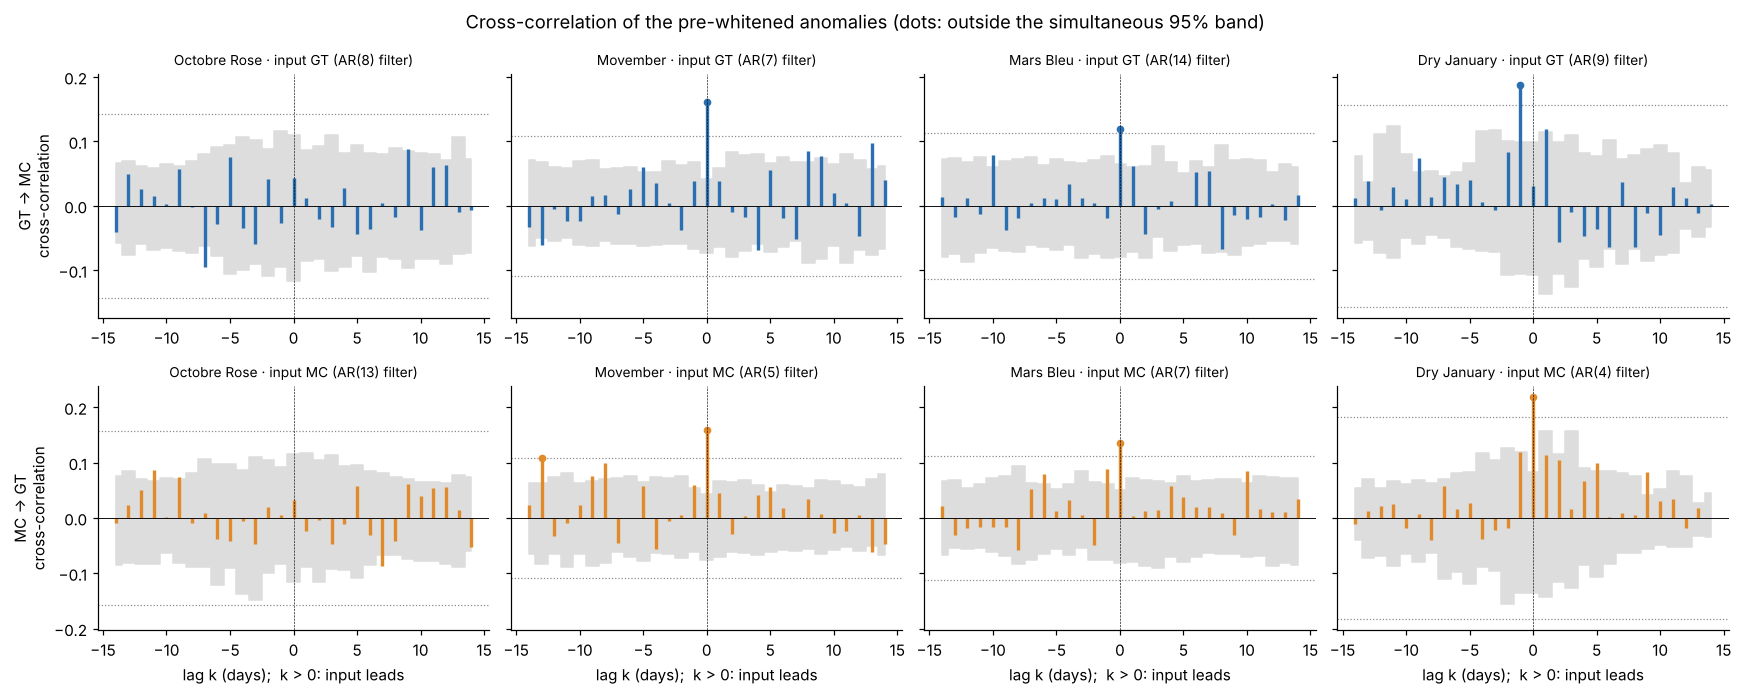

In [6]:
MAX_LAG = 14


def ccf_one(c, x, y):
    X, Y = T.panel(anom[c], x), T.panel(anom[c], y)
    A, B, p = T.prewhiten(X, Y)
    return dict(obs=T.ccf(A, B, MAX_LAG), null=T.ccf_null(A, B, MAX_LAG, n=N_SURR, seed=0), p=p)


ccfs = cached("ccf", lambda: {(c, lab): ccf_one(c, x, y) for c in CODES for x, y, lab in DIRS})

fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), sharey="row")
ccf_rows = []
for i, (x, y, lab) in enumerate(DIRS):
    for j, c in enumerate(CODES):
        r = ccfs[c, lab]
        ax = axes[i, j]
        lags = r["obs"].index.to_numpy()
        lo, hi = np.percentile(r["null"], [2.5, 97.5], axis=0)
        sim_band = np.percentile(np.abs(r["null"] - r["null"].mean(0)).max(1), 95)
        ax.fill_between(lags, lo, hi, color="#dddddd", step="mid")
        ax.axhline(sim_band, color="#888888", lw=0.8, ls=":")
        ax.axhline(-sim_band, color="#888888", lw=0.8, ls=":")
        sig = np.abs(r["obs"].to_numpy()) > sim_band
        ax.vlines(lags, 0, r["obs"], color=DIR_COLOR[lab], lw=2.2)
        ax.plot(lags[sig], r["obs"].to_numpy()[sig], "o", color=DIR_COLOR[lab], ms=4)
        ax.axhline(0, color="black", lw=0.6)
        ax.axvline(0, color="black", lw=0.4, ls="--")
        ax.set_title(f"{LABEL[c]} · input {x.upper()} (AR({r['p']}) filter)", fontsize=9)
        if i == 1:
            ax.set_xlabel(f"lag k (days);  k > 0: input leads")
        for k, v, s in zip(lags, r["obs"], sig):
            ccf_rows.append({"campaign": LABEL[c], "input": x.upper(), "output": y.upper(), "lag": k,
                             "ccf": v, "null_lo": lo[k + MAX_LAG], "null_hi": hi[k + MAX_LAG],
                             "simultaneous_band": sim_band, "outside_simultaneous_band": bool(s)})
    axes[i, 0].set_ylabel(f"{lab}\ncross-correlation")
fig.suptitle("Cross-correlation of the pre-whitened anomalies (dots: outside the simultaneous 95% band)")
fig.tight_layout()
fig.savefig(FIG_DIR / "tf02_prewhitened_ccf.png", dpi=200, bbox_inches="tight")
ccf_table = pd.DataFrame(ccf_rows)
ccf_table.to_csv(TAB_DIR / "tf_prewhitened_ccf.csv", index=False)
ccf_table[ccf_table["outside_simultaneous_band"]].round(3)

## 4. Transfer-function estimates

For each campaign and direction:

* the **distributed-lag** weights $\nu_0,\dots,\nu_{14}$, summarised by the same-day weight
  $\nu_0$ and the lagged response $\nu_1+\dots+\nu_{14}$ (points of the output, cumulated
  over two weeks, per point of the input on one day);
* the **delay + decay** model, with its delay $b$ chosen by AIC among 0–7 days;
* the share of the output's unpredicted variance (what its own AR model leaves) explained
  by the input: `r2_total` with lags 0–14, `r2_lagged` for lags 1–14 beyond the same-day term;
* 95% intervals from the delete-one-season jackknife (Student $t$, 10 degrees of freedom;
  the calendar profile, the noise order and the delay are re-estimated in every replicate);
* p-values against 999 season-swap surrogates, Holm-adjusted across the eight pairs.

In [7]:
def real_one(c, x, y, lab, seed):
    est = T.tf_summary(data[c], x, y)
    jk = T.jackknife(data[c], T.tf_summary, x=x, y=y)
    null = T.season_swap_null(data[c], x, y, n=N_SURR, seed=seed, p=est["p"])
    X, Y = T.panel(anom[c], x), T.panel(anom[c], y)
    rat = T.select_tf(X, Y, p=est["p"])
    return dict(campaign=LABEL[c], code=c, direction=lab, est=est, jk=jk, null=null,
                checks=T.residual_checks(X, Y, rat))


real = cached("real", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(real_one)(c, x, y, lab, 100 + i)
    for i, (c, (x, y, lab)) in enumerate((c, d) for c in CODES for d in DIRS)))

rows = []
for r in real:
    e, jk, null = r["est"], r["jk"], r["null"]
    row = {"campaign": r["campaign"], "direction": r["direction"], "p_noise": e["p"], "n": e["n"]}
    for k in ("same_day", "lagged", "total", "cum"):
        se, lo, hi = T.jackknife_interval(e[k], jk[k])
        row.update({k: e[k], f"{k}_lo": lo, f"{k}_hi": hi})
    row.update({"delay_b": e["b"], "delay_b_jackknife": "/".join(map(str, sorted(jk["b"].astype(int)))),
                "omega": e["omega"], "delta": e["delta"], "half_life": e["half_life"],
                "r2_total": e["r2_total"], "r2_lagged": e["r2_lagged"], "r2_rational": e["r2_rational"],
                "r2_lagged_null_mean": null["r2_lagged"].mean(),
                "p_lagged_fit": T.upper_p(e["r2_lagged"], null["r2_lagged"]),
                "p_lagged_sum": T.two_sided_p(e["lagged"], null["lagged"]),
                "p_same_day": T.two_sided_p(e["same_day"], null["same_day"]),
                "ljung_box_p": r["checks"]["p_ljung_box"], "cross_check_p": r["checks"]["p_cross"]})
    rows.append(row)
tf = pd.DataFrame(rows)
for k in ("p_lagged_fit", "p_lagged_sum", "p_same_day"):
    tf[f"{k}_holm"] = holm(tf[k])
tf.to_csv(TAB_DIR / "tf_estimates.csv", index=False)


def ci(row, k, d=2):
    return f"{row[k]:.{d}f} [{row[k + '_lo']:.{d}f}, {row[k + '_hi']:.{d}f}]"


view = pd.DataFrame({
    "campaign": tf["campaign"], "direction": tf["direction"],
    "same-day ν0": [ci(r, "same_day") for _, r in tf.iterrows()],
    "lagged Σν1..14": [ci(r, "lagged") for _, r in tf.iterrows()],
    "R² lagged": tf["r2_lagged"].round(3), "(surrogates)": tf["r2_lagged_null_mean"].round(3),
    "p lagged fit (Holm)": tf["p_lagged_fit_holm"].round(3),
    "p lagged sum (Holm)": tf["p_lagged_sum_holm"].round(3),
    "p same day (Holm)": tf["p_same_day_holm"].round(3),
    "delay b": tf["delay_b"], "δ": tf["delta"].round(2), "half-life (d)": tf["half_life"].round(1)})
view

[real] computed in 756s


,campaign,direction,same-day ν0,lagged Σν1..14,R² lagged,(surrogates),p lagged fit (Holm),p lagged sum (Holm),p same day (Holm),delay b,δ,half-life (d)
0,Octobre Rose,GT → MC,"0.07 [-0.35, 0.49]","0.11 [-0.95, 1.16]",0.025,0.030,1.000,1.000,1.000,6,0.00,0.0
1,Octobre Rose,MC → GT,"0.01 [-0.06, 0.07]","0.00 [-0.15, 0.15]",0.038,0.026,0.870,1.000,1.000,7,0.15,0.4
2,Movember,GT → MC,"0.51 [0.07, 0.94]","0.60 [0.09, 1.10]",0.041,0.020,0.088,0.784,0.008,0,0.27,0.5
3,Movember,MC → GT,"0.05 [0.00, 0.10]","0.01 [-0.10, 0.11]",0.018,0.015,1.000,1.000,0.008,0,0.17,0.4
4,Mars Bleu,GT → MC,"0.26 [0.02, 0.50]","-0.09 [-0.38, 0.20]",0.019,0.016,1.000,1.000,0.008,0,0.20,0.4
5,Mars Bleu,MC → GT,"0.06 [0.01, 0.12]","0.10 [-0.18, 0.37]",0.017,0.019,1.000,1.000,0.008,0,0.00,0.0
6,Dry January,GT → MC,"0.18 [-0.02, 0.38]","-0.07 [-0.74, 0.61]",0.034,0.044,1.000,1.000,0.008,0,0.29,0.6
7,Dry January,MC → GT,"0.16 [-0.05, 0.36]","0.60 [0.20, 1.01]",0.061,0.035,0.413,0.024,0.008,0,0.77,2.6


### 4.1 Impulse-response weights

Bars: distributed-lag weights $\nu_k$ with 95% jackknife intervals. Line: the delay + decay
model. Grey band: 95% range of each weight over the season-swap surrogates. The first bar
(lag 0, hatched) is the same-day association.

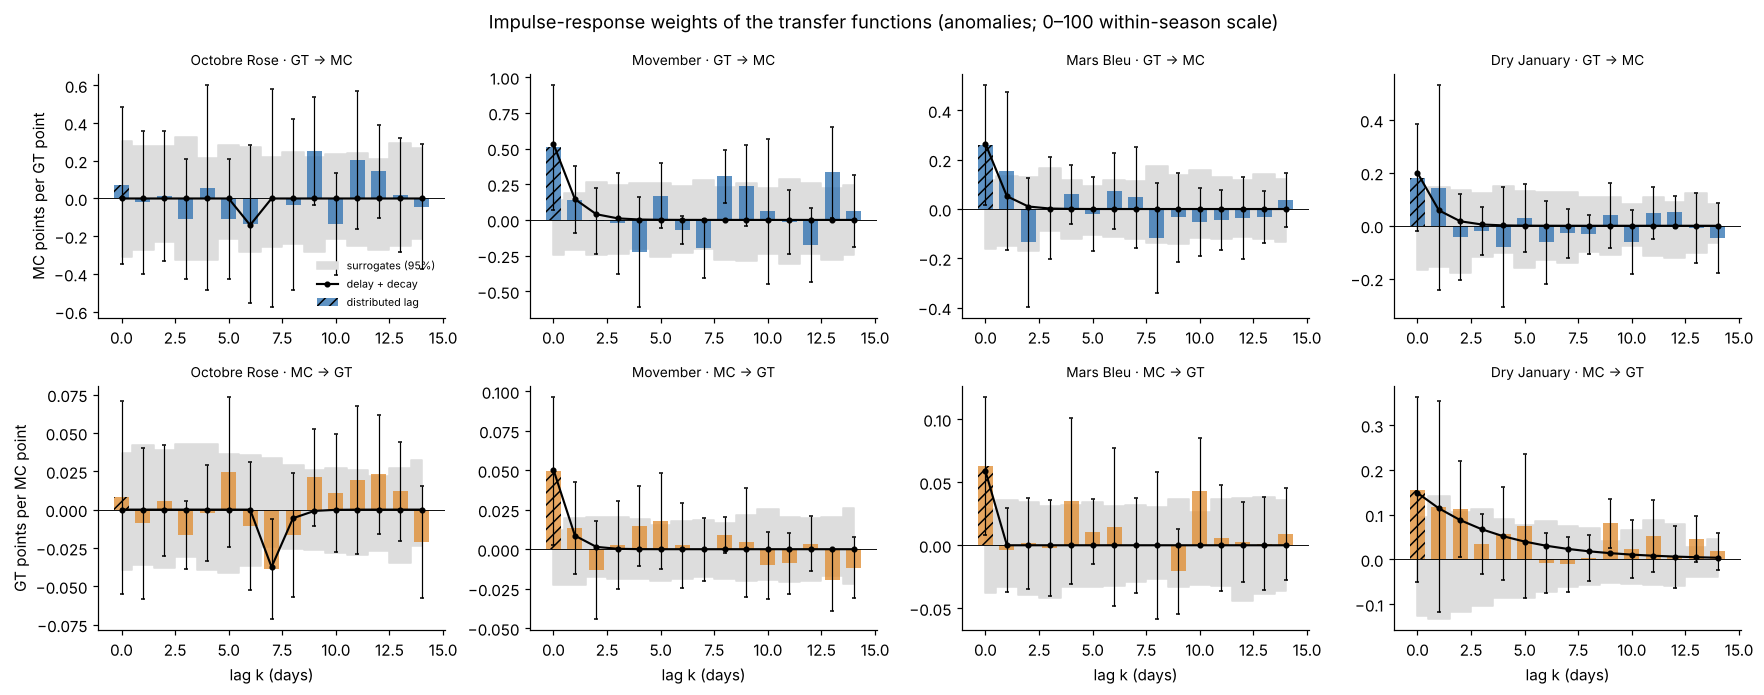

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4))
w_rows = []
for r in real:
    i = [d[2] for d in DIRS].index(r["direction"])
    j = CODES.index(r["code"])
    ax = axes[i, j]
    e, jk, null = r["est"], r["jk"], r["null"]
    lags = np.arange(HORIZON + 1)
    nu = np.array([e[f"nu_{k}"] for k in lags])
    iv = np.array([T.jackknife_interval(e[f"nu_{k}"], jk[f"nu_{k}"])[1:] for k in lags])
    nlo, nhi = np.percentile(null[[f"nu_{k}" for k in lags]].to_numpy(), [2.5, 97.5], axis=0)
    color = DIR_COLOR[r["direction"]]
    ax.fill_between(lags, nlo, nhi, color="#dddddd", step="mid", label="surrogates (95%)")
    bars = ax.bar(lags, nu, 0.7, color=color, alpha=0.75, label="distributed lag")
    bars[0].set_hatch("///")
    ax.errorbar(lags, nu, yerr=[nu - iv[:, 0], iv[:, 1] - nu], fmt="none", ecolor="black", lw=0.8, capsize=1.5)
    rat = e["omega"] * e["delta"] ** np.clip(lags - e["b"], 0, None) * (lags >= e["b"])
    ax.plot(lags, rat, color="black", lw=1.4, marker=".", label="delay + decay")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{r['campaign']} · {r['direction']}", fontsize=9)
    if i == 1:
        ax.set_xlabel("lag k (days)")
    for k in lags:
        w_rows.append({"campaign": r["campaign"], "direction": r["direction"], "lag": k, "nu": nu[k],
                       "ci_low": iv[k, 0], "ci_high": iv[k, 1], "null_lo": nlo[k], "null_hi": nhi[k],
                       "delay_decay": rat[k]})
axes[0, 0].set_ylabel("MC points per GT point")
axes[1, 0].set_ylabel("GT points per MC point")
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Impulse-response weights of the transfer functions (anomalies; 0–100 within-season scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "tf03_impulse_weights.png", dpi=200, bbox_inches="tight")
pd.DataFrame(w_rows).to_csv(TAB_DIR / "tf_impulse_weights.csv", index=False)

### 4.2 Lagged response and its surrogate distribution

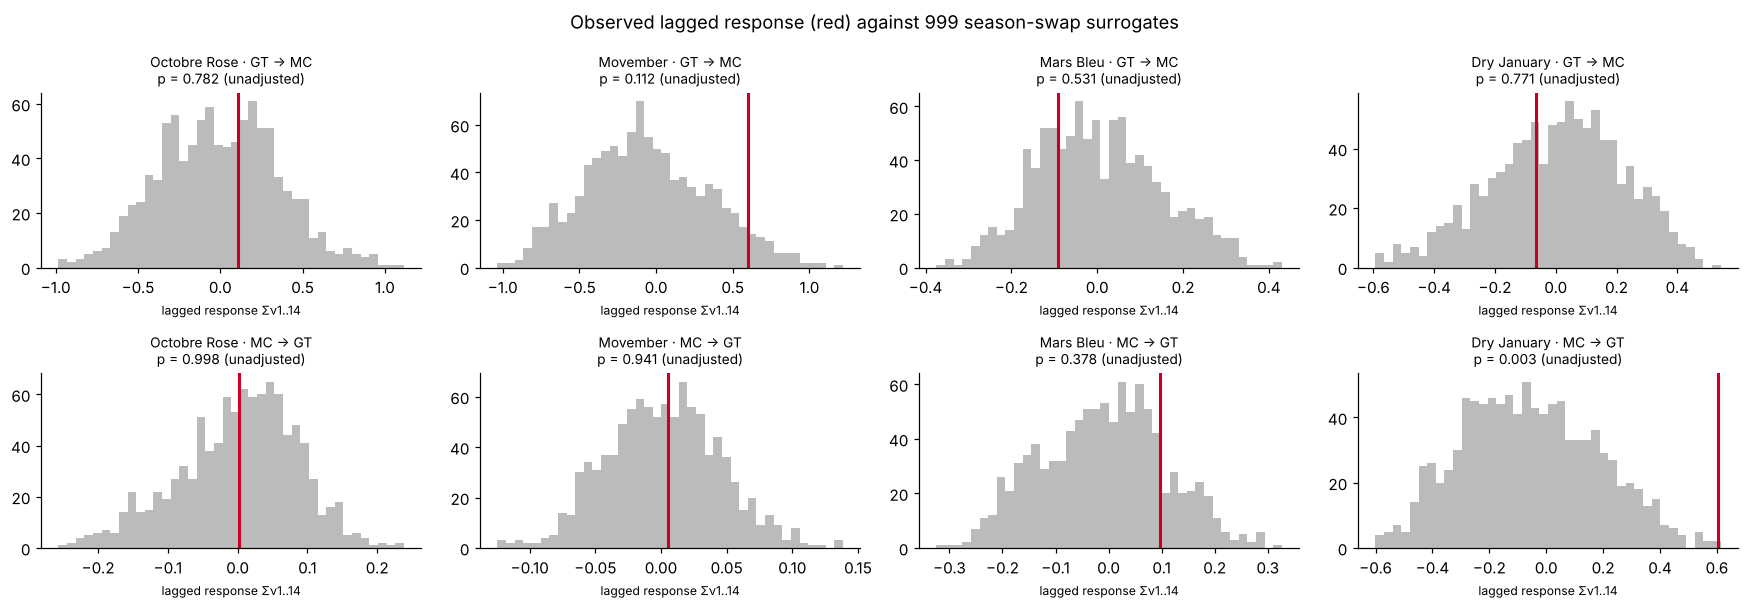

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 5.6))
for r in real:
    ax = axes[[d[2] for d in DIRS].index(r["direction"]), CODES.index(r["code"])]
    ax.hist(r["null"]["lagged"], bins=40, color="#bbbbbb")
    ax.axvline(r["est"]["lagged"], color="#ca0020", lw=2)
    row = tf[(tf["campaign"] == r["campaign"]) & (tf["direction"] == r["direction"])].iloc[0]
    ax.set_title(f"{r['campaign']} · {r['direction']}\np = {row['p_lagged_sum']:.3f} (unadjusted)", fontsize=9)
    ax.set_xlabel("lagged response Σν1..14", fontsize=8)
fig.suptitle(f"Observed lagged response (red) against {N_SURR} season-swap surrogates")
fig.tight_layout()
fig.savefig(FIG_DIR / "tf04_lagged_response_null.png", dpi=200, bbox_inches="tight")

### 4.3 Diagnostic checks

Two Box–Jenkins checks of the delay + decay models: the residuals should be uncorrelated in
time (Ljung–Box statistic, noise model adequate) and uncorrelated with the pre-whitened
input at lags 0–14 (transfer function adequate). Their chi-square p-values treat days as
independent draws and are therefore indicative. `r2_rational` against `r2_total` shows how
much of what the 15 free weights explain is kept by the two-parameter model.

In [10]:
tf[["campaign", "direction", "p_noise", "delay_b", "delay_b_jackknife", "omega", "delta", "half_life",
    "cum", "cum_lo", "cum_hi", "r2_rational", "r2_total", "ljung_box_p", "cross_check_p"]].round(3)

,campaign,direction,p_noise,delay_b,delay_b_jackknife,omega,delta,half_life,cum,cum_lo,cum_hi,r2_rational,r2_total,ljung_box_p,cross_check_p
0,Octobre Rose,GT → MC,6,6,0/0/5/5/5/6/6/6/6/7/7,-0.141,0.000,0.018,-0.141,-1.723,1.441,0.003,0.025,0.003,0.064
1,Octobre Rose,MC → GT,7,7,5/7/7/7/7/7/7/7/7/7/7,-0.037,0.150,0.365,-0.044,-0.226,0.138,0.011,0.039,0.034,0.011
2,Movember,GT → MC,5,0,0/0/0/0/0/0/0/0/0/0/0,0.531,0.274,0.535,0.732,0.196,1.268,0.029,0.066,0.375,0.001
3,Movember,MC → GT,7,0,0/0/0/0/0/0/0/0/0/0/0,0.050,0.171,0.392,0.061,-0.006,0.128,0.028,0.044,0.575,0.366
4,Mars Bleu,GT → MC,7,0,0/0/0/0/0/0/0/0/0/0/0,0.264,0.197,0.426,0.329,-0.013,0.670,0.021,0.038,0.085,0.140
5,Mars Bleu,MC → GT,7,0,0/0/0/0/0/0/0/0/0/0/0,0.059,0.000,0.020,0.059,0.004,0.113,0.015,0.032,0.000,0.386
6,Dry January,GT → MC,1,0,0/0/0/0/0/0/0/0/0/0/4,0.200,0.291,0.562,0.282,-0.671,1.235,0.039,0.065,0.764,0.470
7,Dry January,MC → GT,6,0,0/0/0/0/0/0/0/0/0/0/1,0.148,0.768,2.630,0.628,0.281,0.974,0.057,0.079,0.107,0.799


## 5. Sensitivity to the choices made

The distributed-lag summaries are recomputed with
(a) the main specification; (b) no season-level term; (c) no day-of-week term;
(d) the campaign profile only; (e) a horizon of 7 days; (f) a horizon of 21 days.
Variants (c) and (d) leave the shared weekly cycle in the anomalies.

In [11]:
VARIANTS = {"main": dict(), "no season level": dict(season=False), "no weekday": dict(weekday=False),
            "profile only": dict(weekday=False, season=False),
            "horizon 7": dict(horizon=7), "horizon 21": dict(horizon=21)}


def sens_one(c, x, y, lab, name):
    e = T.tf_summary(data[c], x, y, **VARIANTS[name])
    return {"campaign": LABEL[c], "direction": lab, "variant": name, "same_day": e["same_day"],
            "lagged": e["lagged"], "r2_lagged": e["r2_lagged"], "b": e["b"], "delta": e["delta"]}


sens = cached("sensitivity", lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(
    delayed(sens_one)(c, x, y, lab, name) for c in CODES for x, y, lab in DIRS for name in VARIANTS)))
sens.to_csv(TAB_DIR / "tf_sensitivity.csv", index=False)
sens.pivot(index=["campaign", "direction"], columns="variant", values="lagged")[list(VARIANTS)].round(2)

[sensitivity] computed in 6s


variant                 main  no season level  no weekday  profile only  horizon 7  horizon 21
campaign     direction                                                                        
Dry January  GT → MC   -0.07             0.34       -0.07          0.33      -0.06       -0.11
             MC → GT    0.60             0.48        0.60          0.48       0.30        0.77
Mars Bleu    GT → MC   -0.09            -0.04       -0.11         -0.08       0.03       -0.19
             MC → GT    0.10             0.08        0.10          0.09       0.05        0.26
Movember     GT → MC    0.60             0.18        0.54          0.14      -0.05        0.15
             MC → GT    0.01             0.02        0.01          0.03       0.04       -0.01
Octobre Rose GT → MC    0.11            -0.22        0.07         -0.33      -0.19        0.04
             MC → GT    0.00            -0.03        0.01         -0.01      -0.06        0.06

In [12]:
sens.pivot(index=["campaign", "direction"], columns="variant", values="same_day")[list(VARIANTS)].round(2)

variant                 main  no season level  no weekday  profile only  horizon 7  horizon 21
campaign     direction                                                                        
Dry January  GT → MC    0.18             0.20        0.19          0.21       0.19        0.18
             MC → GT    0.16             0.15        0.16          0.15       0.14        0.16
Mars Bleu    GT → MC    0.26             0.26        0.31          0.30       0.25        0.26
             MC → GT    0.06             0.06        0.10          0.10       0.06        0.06
Movember     GT → MC    0.51             0.49        0.59          0.57       0.55        0.51
             MC → GT    0.05             0.05        0.06          0.06       0.05        0.05
Octobre Rose GT → MC    0.07             0.05        0.21          0.18       0.07        0.07
             MC → GT    0.01             0.01        0.03          0.02       0.01        0.01

## 6. Frequency domain

The same question by period instead of by lag. With one Hann-tapered segment per season,
the **squared coherence** is the share of the variance of one series linearly related to
the other at each period, and the **phase** gives the delay between them. With 11 seasons,
two unrelated series reach a squared coherence of 0.26 at a given frequency 5% of the time
(dashed line).

Three curves per campaign: the raw series, the raw series with seasons swapped (average
over 200 swaps: what the calendar alone produces), and the anomalies.

[spectra] computed in 0s


,frequencies,above_threshold,max_coherence
campaign,,,
Octobre Rose,45,3,0.377
Movember,46,9,0.378
Mars Bleu,44,3,0.359
Dry January,21,3,0.400


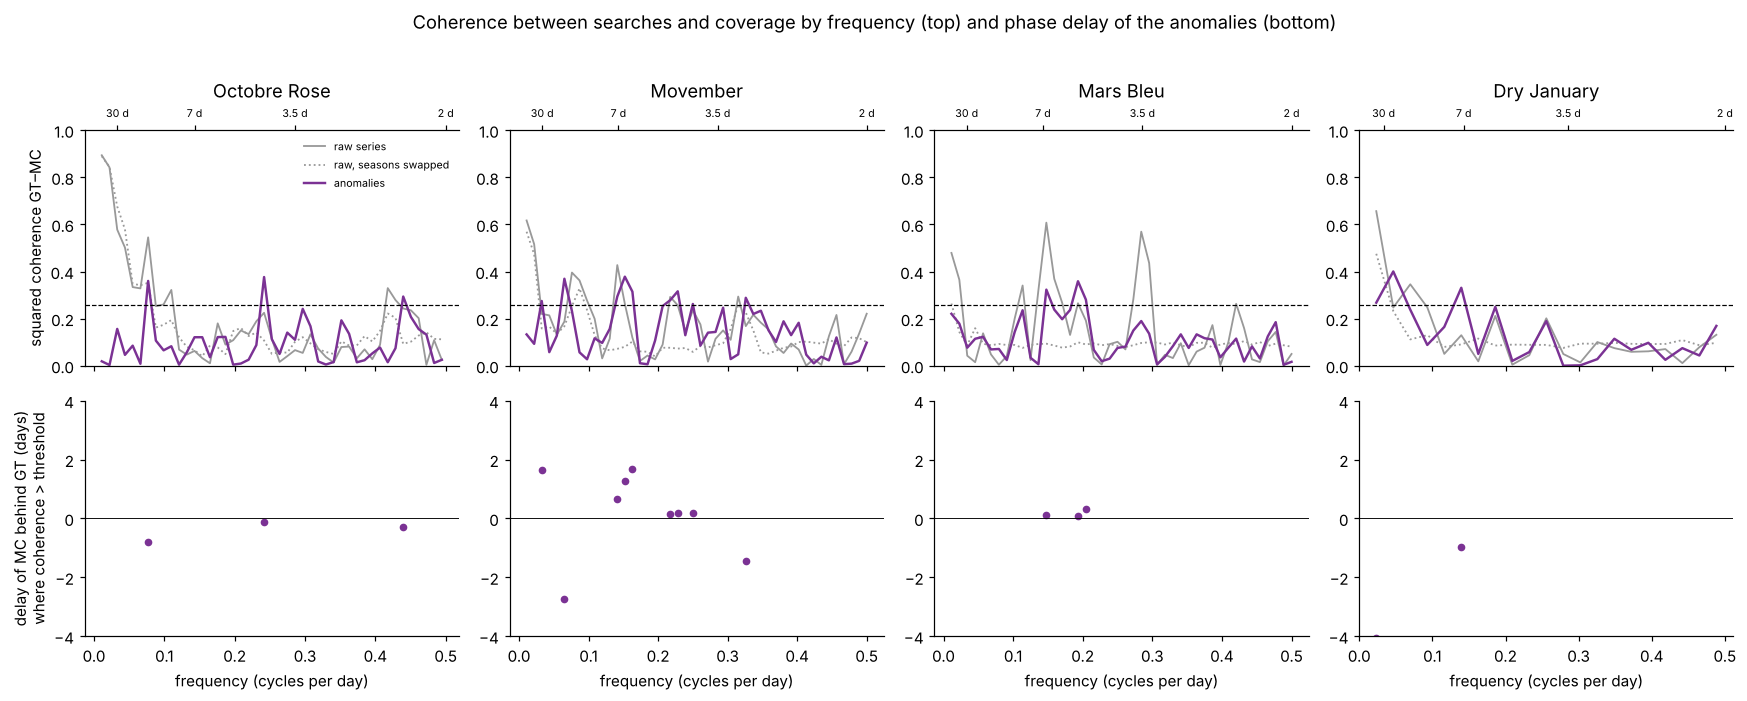

In [13]:
def spectra(c, n_swap=200, seed=0):
    G, M = T.panel(data[c], "gt"), T.panel(data[c], "mc")
    raw = T.cross_spectrum(G, M)
    rng = np.random.default_rng(seed)
    swapped = np.mean([T.cross_spectrum(T.swap(G, p), M)["coherence"].to_numpy()
                       for p in T.derangements(G.shape[0], n_swap, rng)], axis=0)
    an = T.cross_spectrum(T.panel(anom[c], "gt"), T.panel(anom[c], "mc"))
    return raw, swapped, an


spec = cached("spectra", lambda: {c: spectra(c) for c in CODES})
thr = T.coherence_threshold(11)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.2), sharex="col")
spec_rows = []
for j, c in enumerate(CODES):
    raw, swapped, an = spec[c]
    ax = axes[0, j]
    ax.plot(raw["freq"], raw["coherence"], color="#999999", lw=1.2, label="raw series")
    ax.plot(raw["freq"], swapped, color="#999999", lw=1.2, ls=":", label="raw, seasons swapped")
    ax.plot(an["freq"], an["coherence"], color="#7b3294", lw=1.6, label="anomalies")
    ax.axhline(thr, color="black", lw=0.8, ls="--")
    ax.set(title=LABEL[c], ylim=(0, 1))
    ok = an["coherence"] > thr
    axes[1, j].plot(an["freq"][ok], an["delay"][ok], "o", color="#7b3294", ms=4)
    axes[1, j].axhline(0, color="black", lw=0.6)
    axes[1, j].set(xlabel="frequency (cycles per day)", ylim=(-4, 4))
    sec = axes[0, j].secondary_xaxis("top", functions=(lambda f: f, lambda f: f))
    ticks = [1 / 30, 1 / 7, 1 / 3.5, 0.5]
    sec.set_xticks(ticks, ["30 d", "7 d", "3.5 d", "2 d"], fontsize=7)
    for _, row in an.iterrows():
        spec_rows.append({"campaign": LABEL[c], **row.to_dict(), "above_threshold": bool(row["coherence"] > thr)})
axes[0, 0].set_ylabel("squared coherence GT–MC")
axes[1, 0].set_ylabel("delay of MC behind GT (days)\nwhere coherence > threshold")
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Coherence between searches and coverage by frequency (top) and phase delay of the anomalies (bottom)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "tf05_coherence.png", dpi=200, bbox_inches="tight")
spec_table = pd.DataFrame(spec_rows)
spec_table.to_csv(TAB_DIR / "tf_coherence.csv", index=False)
spec_table.groupby("campaign", sort=False).agg(
    frequencies=("coherence", "size"), above_threshold=("above_threshold", "sum"),
    max_coherence=("coherence", "max")).round(3)

## 7. Conclusions

**Validation (Section 2).** On simulated systems the procedure recovers a known transfer
function without bias (lagged response 1.25 against a true 1.249; coverage of the 95%
jackknife interval 96/100; delay of one day selected 100/100; median half-life 1.37 days
against 1.36). With no link and a fixed calendar its rejection rates are 1–10%.
Two weaknesses: the *lagged sum* statistic is liberal in the direction without a link
when the other direction has one (28% rejections); and when the timing of the campaign
pulse varies from year to year, calendar removal is incomplete and the tests reject far
too often (53% for GT → MC, 92–94% for the lagged tests of MC → GT). The *lagged fit*
statistic is therefore the primary one, and no test here can exclude a common driver
whose date changes between years.

**What remains after removing the calendar (Sections 3–6).**
1. A **same-day association** for Movember, Mars Bleu and Dry January: positive, with a
   surrogate p-value of 0.001 (0.002 for Dry January GT → MC; Holm-adjusted 0.008 in all
   cases), with a delay of 0
   days and a half-life under 0.6 days. It has no direction. Octobre Rose shows none.
2. **Lagged responses are weak.** Movember GT → MC: lagged response 0.60 (jackknife 0.09 to
   1.10), borderline against surrogates (lagged fit, Holm-adjusted p = 0.088). Dry January
   MC → GT: lagged response 0.60 (0.20 to 1.01), delay + decay with gain 0.64 and
   half-life 2.6 days; the lagged-sum test is significant (Holm-adjusted p = 0.024) but the
   lagged-fit test is not (0.41), and the window has 43 days per season. A candidate, not a
   result.
3. **Frequency domain.** Low-frequency coherence of the raw series is the campaign profile
   (it is as high with seasons swapped). In the anomalies only Movember has more
   frequencies above the 5% level than chance (9 of 46), with no consistent phase delay.

**Reading.** At daily resolution the two channels are coupled in the *same* day, not with
a delay of one to several days. A delayed response of searches to coverage (or the
reverse), the quantity a transfer function would add to the Granger analysis, is not
established for any campaign. The synchronous association is what a shared event (a news
item, a celebrity post) produces, and it is also what quick mutual reactions produce; the
data cannot distinguish them.
